<a href="https://colab.research.google.com/github/Divyesh-SP/DSA0405-FUNDAMENTALS-OF-DATA-SCIENCE/blob/main/DSA04_CO3_Farm_Yield_Income_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA04 – Fundamentals of Data Science (CO3)
## Farm Yield and Income: Descriptive Statistics Study

**Run in Google Colab:** Upload this notebook and choose Runtime → Run all.

This notebook creates a reproducible synthetic survey of 12,000 farms in Dry, Delta and Hill districts, injects the data-quality problems required by the assignment, and implements Tasks 1–11. It creates tables, statistical tests and plots. The 800-farm verification sample is selected randomly from the generated survey.

**Important:** This is synthetic teaching data, not real agricultural or financial evidence. Use the actual results printed by your own run in your report.

## Setup and imports

In [1]:
import os, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import trim_mean, skew, kurtosis, lognorm, norm, gamma
from IPython.display import display

SEED=42
rng=np.random.default_rng(SEED)
np.random.seed(SEED)
OUT=Path("DSA04_CO3_outputs")
OUT.mkdir(exist_ok=True)
print("Python:",platform.python_version())
print("NumPy:",np.__version__,"Pandas:",pd.__version__)
print("Random seed:",SEED)

Python: 3.13.18
NumPy: 2.4.6 Pandas: 2.2.3
Random seed: 42


## Generate the 12,000-farm synthetic survey

In [2]:
N=12000
districts=np.array(["Dry","Delta","Hill"])
district=rng.choice(districts,N,p=[.34,.40,.26])
crop=rng.choice(["Rice","Millet","Wheat","Vegetable"],N,p=[.38,.24,.20,.18])
irrigation=rng.choice(["Canal","Borewell","Rainfed"],N,p=[.35,.35,.30])
soil=rng.choice(["Alluvial","Black","Red","Mountain"],N,p=[.32,.25,.30,.13])
district_rain={"Dry":480,"Delta":1050,"Hill":820}
rainfall=np.array([rng.normal(district_rain[d],130) for d in district])
rainfall=np.clip(rainfall,100,1600)
farm_size=np.clip(rng.lognormal(mean=1.0,sigma=.65,size=N),.2,80)
# Inject genuine large commercial farms
large_idx=rng.choice(N,80,replace=False)
farm_size[large_idx]=rng.uniform(90,180,len(large_idx))
fertiliser=np.clip(rng.normal(85,22,N),10,180)
seed_cost=np.clip(farm_size*rng.normal(1250,180,N),100,500000)
household_size=rng.integers(2,10,N)
# Nonlinear rainfall response: yield rises then levels/falls at excess rain
rain_effect=1.0 + .0009*rainfall - .00000055*(rainfall-850)**2
district_effect=pd.Series(district).map({"Dry":-0.8,"Delta":1.2,"Hill":0.3}).to_numpy()
crop_effect=pd.Series(crop).map({"Rice":2.0,"Millet":-0.5,"Wheat":0.5,"Vegetable":3.0}).to_numpy()
yield_qpa=np.maximum(.2, 12 + rain_effect*5 + district_effect + crop_effect + .025*fertiliser + rng.normal(0,2.2,N))
income=np.exp(rng.normal(10.3,.75,N))*farm_size/4
income*=pd.Series(crop).map({"Rice":1.0,"Millet":.72,"Wheat":.9,"Vegetable":1.35}).to_numpy()
loan=np.exp(rng.normal(9.0,.9,N))*np.sqrt(farm_size)
survey=pd.DataFrame({
 "farm_id":[f"F{i:05d}" for i in range(1,N+1)],"district":district,"crop":crop,
 "farm_size_acres":farm_size,"irrigation_type":irrigation,"soil_type":soil,
 "household_size":household_size,"rainfall_mm":rainfall,"fertiliser_kg_per_acre":fertiliser,
 "seed_cost":seed_cost,"yield_q_per_acre":yield_qpa,"income_per_season":income,
 "loan_amount":loan
})
# Inject required quality problems
income_missing=rng.choice(survey.index,int(.09*N),replace=False)
survey.loc[income_missing,"income_per_season"]=np.nan
fert_missing=rng.choice(survey.index,int(.06*N),replace=False)
survey.loc[fert_missing,"fertiliser_kg_per_acre"]=np.nan
unit_idx=rng.choice(survey.index,100,replace=False)
survey.loc[unit_idx,"income_per_season"]*=1000
zero_idx=rng.choice(survey.index,25,replace=False)
survey.loc[zero_idx,"farm_size_acres"]=0
huge_idx=rng.choice(survey.index,25,replace=False)
survey.loc[huge_idx,"farm_size_acres"]=400
neg_idx=rng.choice(survey.index,30,replace=False)
survey.loc[neg_idx,"yield_q_per_acre"]=-abs(survey.loc[neg_idx,"yield_q_per_acre"])
# Inconsistent labels
label_idx=rng.choice(survey.index,150,replace=False)
survey.loc[label_idx,"district"]=survey.loc[label_idx,"district"].replace({"Dry":"dry ","Delta":"DELTA","Hill":"hill"})
# Duplicate records
survey=pd.concat([survey,survey.sample(60,random_state=SEED)],ignore_index=True)
# Select 800 verification IDs from unique farm records
verification=survey.drop_duplicates("farm_id").sample(800,random_state=SEED).copy()
survey.to_csv(OUT/"farm_survey_raw.csv",index=False)
verification.to_csv(OUT/"verification_sample_raw.csv",index=False)
print("Raw survey rows (including duplicates):",len(survey))
print("Unique farms:",survey.farm_id.nunique())
print("Verification sample:",len(verification))
display(survey.head())

Raw survey rows (including duplicates): 12060
Unique farms: 12000
Verification sample: 800


,farm_id,district,crop,farm_size_acres,irrigation_type,soil_type,household_size,rainfall_mm,fertiliser_kg_per_acre,seed_cost,yield_q_per_acre,income_per_season,loan_amount
0,F00001,Hill,Millet,3.018286,Rainfed,Red,3,718.752666,25.626620,3875.927144,24.695458,19921.950886,7669.327444
1,F00002,Delta,Rice,4.546563,Borewell,Alluvial,9,1126.915052,109.674396,4119.767992,30.147283,18440.340183,40936.099821
2,F00003,Hill,Rice,5.864548,Canal,Black,3,1029.488566,76.784025,7877.616372,23.514962,105573.489126,11939.501753
3,F00004,Delta,Vegetable,3.126008,Canal,Alluvial,9,1235.636566,102.222635,3505.198930,29.385459,33129.090495,48563.055725
4,F00005,Dry,Rice,3.155337,Canal,Black,8,410.993699,81.762717,3943.535777,20.759587,45208.727172,4197.251095


## TASK 1 – Problem formulation and data description

In [3]:
task_map=pd.DataFrame([
 ["Extension planning","Typical yield/income by district and crop","Median and IQR; grouped summaries","12,000 surveyed farms"],
 ["Credit and insurance","Describe heavy tails and unusual farms","Quantiles, skewness and outlier review","12,000 surveyed farms"],
 ["Research","Study factors associated with yield and estimate reliability","Correlation and sampling distributions","Survey population; verification sample n=800"]
],columns=["Team","Statistical question","Suitable method","Population/sample"])
display(task_map)
variable_types=pd.DataFrame([
 ["district","Categorical","Nominal"],["crop","Categorical","Nominal"],["irrigation_type","Categorical","Nominal"],
 ["soil_type","Categorical","Nominal"],["farm_size_acres","Numerical","Ratio / continuous"],
 ["rainfall_mm","Numerical","Ratio / continuous"],["fertiliser_kg_per_acre","Numerical","Ratio / continuous"],
 ["seed_cost","Numerical","Ratio / continuous"],["yield_q_per_acre","Numerical","Ratio / continuous"],
 ["income_per_season","Numerical","Ratio / continuous"],["loan_amount","Numerical","Ratio / continuous"],
 ["household_size","Numerical","Ratio / discrete"]
],columns=["Variable","Type","Measurement scale"])
display(variable_types)
print("Source: synthetic data generated in this notebook.")
print("Attributes:",len(survey.columns),"columns; raw rows:",len(survey))

,Team,Statistical question,Suitable method,Population/sample
0,Extension planning,Typical yield/income by district and crop,Median and IQR; grouped summaries,"12,000 surveyed farms"
1,Credit and insurance,Describe heavy tails and unusual farms,"Quantiles, skewness and outlier review","12,000 surveyed farms"
2,Research,Study factors associated with yield and estima...,Correlation and sampling distributions,Survey population; verification sample n=800


,Variable,Type,Measurement scale
0,district,Categorical,Nominal
1,crop,Categorical,Nominal
2,irrigation_type,Categorical,Nominal
3,soil_type,Categorical,Nominal
4,farm_size_acres,Numerical,Ratio / continuous
5,rainfall_mm,Numerical,Ratio / continuous
6,fertiliser_kg_per_acre,Numerical,Ratio / continuous
7,seed_cost,Numerical,Ratio / continuous
8,yield_q_per_acre,Numerical,Ratio / continuous
9,income_per_season,Numerical,Ratio / continuous


Source: synthetic data generated in this notebook.
Attributes: 13 columns; raw rows: 12060


## TASK 2 – Data preparation and quality audit

In [4]:
raw=survey.copy()
audit=[]
for col in raw.columns:
    audit.append([col,int(raw[col].isna().sum()),round(raw[col].isna().mean()*100,2),int(raw[col].nunique(dropna=True))])
audit_df=pd.DataFrame(audit,columns=["column","missing_count","missing_percent","unique_values"])
display(audit_df)
print("Duplicate farm IDs:",raw.farm_id.duplicated().sum())
print("Zero farm size:",(raw.farm_size_acres==0).sum(),"400-acre entries:",(raw.farm_size_acres==400).sum())
print("Negative yields:",(raw.yield_q_per_acre<0).sum())
# Remove duplicates and normalise labels
clean=raw.drop_duplicates("farm_id",keep="first").copy()
for col in ["district","crop","irrigation_type","soil_type"]:
    clean[col]=clean[col].astype(str).str.strip().str.title()
# Correct unit errors using a documented threshold; flagged records divided by 1000
unit_mask=clean.income_per_season>1_000_000
print("Income unit-error candidates:",int(unit_mask.sum()))
clean.loc[unit_mask,"income_per_season"]/=1000
# Impossible values become missing
clean.loc[clean.farm_size_acres.isin([0,400]),"farm_size_acres"]=np.nan
clean.loc[clean.yield_q_per_acre<0,"yield_q_per_acre"]=np.nan
print("After cleaning rows:",len(clean),"unique IDs:",clean.farm_id.nunique())
print("Remaining invalid farm sizes:",clean.farm_size_acres.le(0).sum())
display(clean[["district","crop","farm_size_acres","yield_q_per_acre","income_per_season"]].describe().round(2))

,column,missing_count,missing_percent,unique_values
0,farm_id,0,0.00,12000
1,district,0,0.00,6
2,crop,0,0.00,4
3,farm_size_acres,0,0.00,11952
4,irrigation_type,0,0.00,3
5,soil_type,0,0.00,4
6,household_size,0,0.00,8
7,rainfall_mm,0,0.00,11993
8,fertiliser_kg_per_acre,725,6.01,11276
9,seed_cost,0,0.00,12000


Duplicate farm IDs: 60
Zero farm size: 25 400-acre entries: 25
Negative yields: 31
Income unit-error candidates: 123
After cleaning rows: 12000 unique IDs: 12000
Remaining invalid farm sizes: 0


,farm_size_acres,yield_q_per_acre,income_per_season
count,11950.00,11970.00,10920.00
mean,4.24,24.03,34331.65
std,11.07,3.39,54063.64
min,0.28,12.53,607.70
25%,1.76,21.71,9628.19
50%,2.73,24.11,19321.02
75%,4.28,26.40,38661.74
max,178.82,34.87,975974.81


## TASK 3 – Data summarisation

In [5]:
main_vars=["farm_size_acres","rainfall_mm","fertiliser_kg_per_acre","seed_cost","yield_q_per_acre","income_per_season","loan_amount"]
def descriptive(s):
    x=s.dropna()
    q=x.quantile([0,.25,.5,.75,1])
    return pd.Series({
      "count":x.count(),"mean":x.mean(),"median":x.median(),"mode":x.mode().iloc[0] if len(x.mode()) else np.nan,
      "trimmed_mean_10pct":trim_mean(x,.10),"min":q.iloc[0],"Q1":q.iloc[1],"Q3":q.iloc[3],"max":q.iloc[4],
      "range":x.max()-x.min(),"variance":x.var(),"std":x.std(),"IQR":x.quantile(.75)-x.quantile(.25),
      "CV_percent":x.std()/x.mean()*100 if x.mean()!=0 else np.nan
    })
summary=pd.DataFrame({v:descriptive(clean[v]) for v in main_vars}).T
display(summary.round(2))
district_crop=clean.groupby(["district","crop"],observed=True).agg(
    farms=("farm_id","nunique"),median_yield=("yield_q_per_acre","median"),
    mean_yield=("yield_q_per_acre","mean"),median_income=("income_per_season","median"),
    mean_income=("income_per_season","mean")).reset_index()
display(district_crop)
print("Recommended: median and IQR for income/loan (right-skewed); mean and SD may be useful for approximately symmetric yield.")
print("A pooled mean income can be misleading because districts and crop types differ; inspect grouped medians.")

,count,mean,median,mode,trimmed_mean_10pct,min,Q1,Q3,max,range,variance,std,IQR,CV_percent
farm_size_acres,11950.0,4.24,2.73,0.28,3.01,0.28,1.76,4.28,178.82,178.55,1.225900e+02,11.07,2.52,261.33
rainfall_mm,12000.0,793.52,830.88,100.00,799.13,100.00,550.26,1018.18,1594.10,1494.10,7.700954e+04,277.51,467.92,34.97
fertiliser_kg_per_acre,11280.0,84.68,84.44,10.00,84.61,10.00,69.87,99.54,173.62,163.62,4.862100e+02,22.05,29.67,26.04
seed_cost,12000.0,5281.95,3385.85,267.24,3733.89,267.24,2149.53,5320.07,271433.24,271166.00,1.921044e+08,13860.17,3170.54,262.41
yield_q_per_acre,11970.0,24.03,24.11,12.53,24.07,12.53,21.71,26.40,34.87,22.35,1.146000e+01,3.39,4.69,14.09
income_per_season,10920.0,34331.65,19321.02,607.70,24195.79,607.70,9628.19,38661.74,975974.81,975367.12,2.922878e+09,54063.64,29033.55,157.47
loan_amount,12000.0,21775.11,13559.00,239.94,16373.74,239.94,7095.74,25587.11,1499684.19,1499444.25,9.779989e+08,31272.97,18491.37,143.62


,district,crop,farms,median_yield,mean_yield,median_income,mean_income
0,Delta,Millet,1132,24.302311,24.384491,14288.145216,26664.980755
1,Delta,Rice,1828,26.863247,26.909200,19863.387376,34865.403071
2,Delta,Vegetable,838,27.656289,27.702844,25894.446946,45090.628228
3,Delta,Wheat,1008,25.388726,25.384151,18764.316390,33743.315422
4,Dry,Millet,980,19.570071,19.568560,14253.656451,23512.181632
5,Dry,Rice,1555,22.085908,22.049099,19936.649445,35299.684432
6,Dry,Vegetable,757,22.864074,23.010778,28138.225382,47890.524296
7,Dry,Wheat,834,20.594255,20.566235,18607.805908,33191.843601
8,Hill,Millet,724,22.345624,22.469670,13754.588333,25298.663686
9,Hill,Rice,1115,25.008943,25.079957,21245.373665,37953.999440


Recommended: median and IQR for income/loan (right-skewed); mean and SD may be useful for approximately symmetric yield.
A pooled mean income can be misleading because districts and crop types differ; inspect grouped medians.


## TASK 4 – Data distributions and SciPy fitting

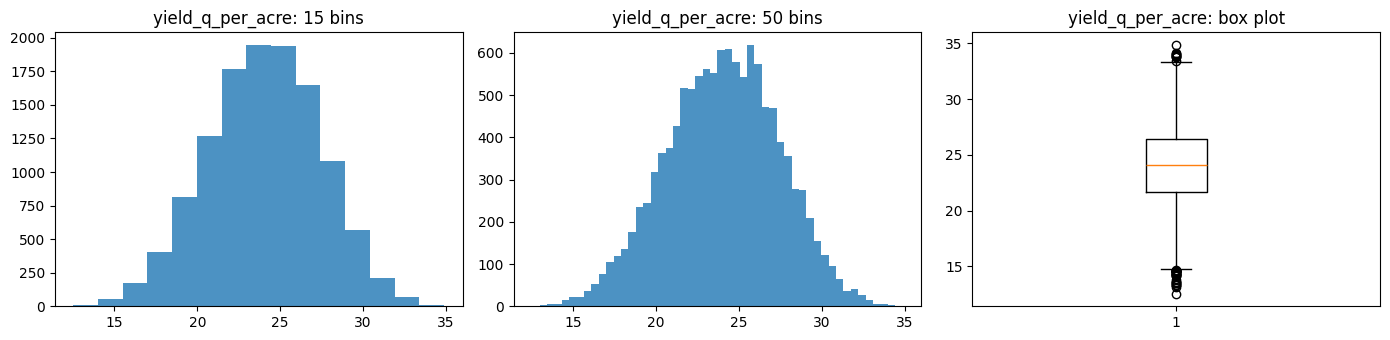

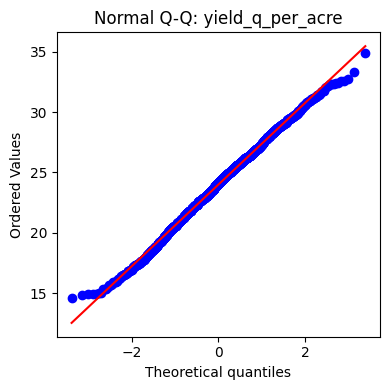

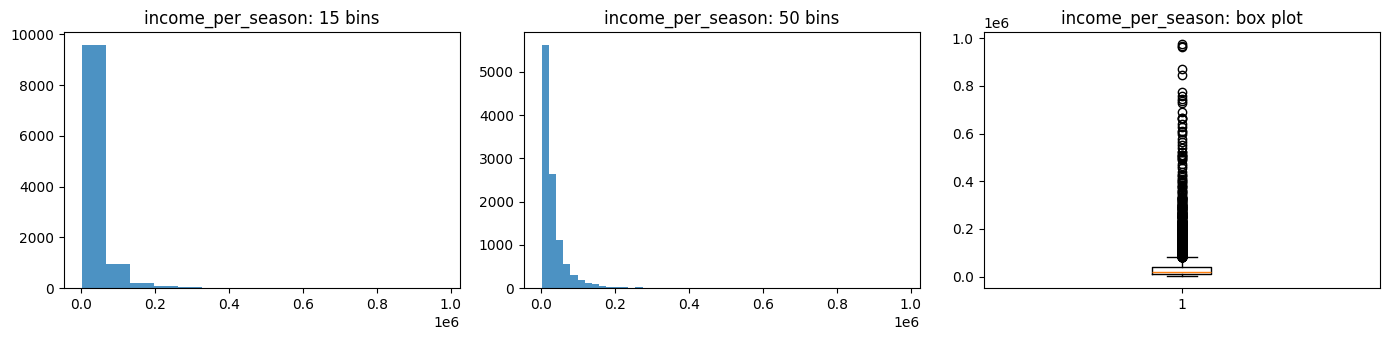

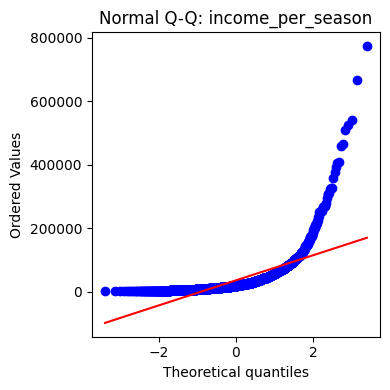

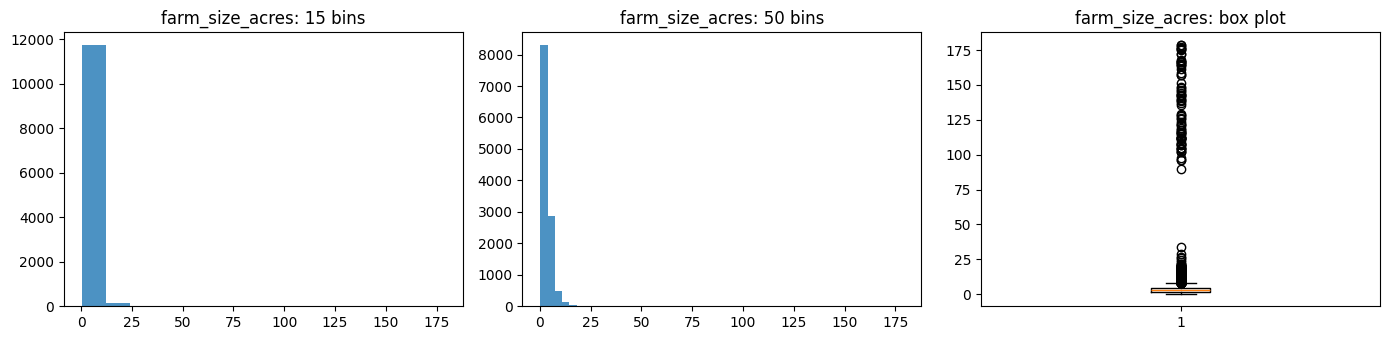

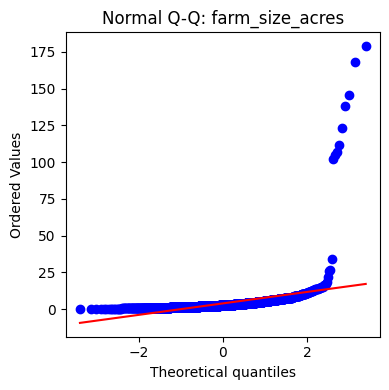

,variable,distribution,fitted_parameters,KS_statistic,KS_p_value
0,yield_q_per_acre,normal,"(24.028602244490983, 3.385021619743729)",0.018523,5.348805e-04
1,yield_q_per_acre,lognormal,"(0.14537559464617755, 0, 23.782021697016713)",0.039155,2.211399e-16
2,income_per_season,normal,"(34331.64734400277, 54061.1683953328)",0.267704,0.000000e+00
3,income_per_season,lognormal,"(1.046109816334696, 0, 19394.205076506794)",0.010327,1.932204e-01


Use overlays and KS values as diagnostics; very large samples can make small deviations statistically significant.


In [6]:
for v in ["yield_q_per_acre","income_per_season","farm_size_acres"]:
    x=clean[v].dropna()
    fig,ax=plt.subplots(1,3,figsize=(14,3.5))
    ax[0].hist(x,bins=15,alpha=.8); ax[0].set_title(f"{v}: 15 bins")
    ax[1].hist(x,bins=50,alpha=.8); ax[1].set_title(f"{v}: 50 bins")
    ax[2].boxplot(x,vert=True); ax[2].set_title(f"{v}: box plot")
    plt.tight_layout(); plt.savefig(OUT/f"task4_{v}_distribution.png",dpi=140); plt.show()
    # Normal Q-Q plot
    plt.figure(figsize=(4,4)); stats.probplot(x.sample(min(2000,len(x)),random_state=SEED),dist="norm",plot=plt)
    plt.title(f"Normal Q-Q: {v}"); plt.tight_layout(); plt.savefig(OUT/f"task4_{v}_qq.png",dpi=140); plt.show()

# Fit normal and lognormal to yield and income; compare KS statistics
fit_rows=[]
for v in ["yield_q_per_acre","income_per_season"]:
    x=clean[v].dropna().to_numpy()
    for name,dist in [("normal",stats.norm),("lognormal",stats.lognorm)]:
        params=dist.fit(x) if name=="normal" else dist.fit(x,floc=0)
        ks=stats.kstest(x,dist.cdf,args=params)
        fit_rows.append([v,name,params,ks.statistic,ks.pvalue])
display(pd.DataFrame(fit_rows,columns=["variable","distribution","fitted_parameters","KS_statistic","KS_p_value"]))
print("Use overlays and KS values as diagnostics; very large samples can make small deviations statistically significant.")

## TASK 5 – Outlier detection and treatment

,method,flagged
0,IQR,894
1,Z-score > 3,169
2,Modified Z-score > 3.5,928


,original,winsorised_99pct,log_transformed
mean,34331.65,32649.31,9.87
median,19321.02,19321.02,9.87
std,54063.64,39967.21,1.05


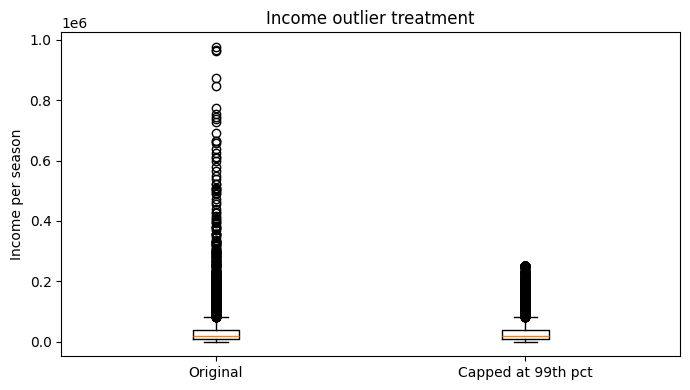

Do not automatically delete flagged farms: verify whether they are unit errors or genuine commercial farms.


In [7]:
x=clean["income_per_season"].dropna()
q1,q3=x.quantile([.25,.75]); iqr=q3-q1
iqr_flag=(x<q1-1.5*iqr)|(x>q3+1.5*iqr)
z_flag=np.abs(stats.zscore(x))>3
med=x.median(); mad=np.median(np.abs(x-med))
modz=0.6745*(x-med)/(mad if mad else 1)
mad_flag=np.abs(modz)>3.5
display(pd.DataFrame({"method":["IQR","Z-score > 3","Modified Z-score > 3.5"],
 "flagged":[iqr_flag.sum(),z_flag.sum(),mad_flag.sum()]}))
# Compare original, capped and log-transformed
upper=x.quantile(.99)
wins=x.clip(upper=upper)
outcome=pd.DataFrame({
 "original":[x.mean(),x.median(),x.std()],
 "winsorised_99pct":[wins.mean(),wins.median(),wins.std()],
 "log_transformed":[np.log1p(x).mean(),np.log1p(x).median(),np.log1p(x).std()]
},index=["mean","median","std"])
display(outcome.round(2))
plt.figure(figsize=(7,4)); plt.boxplot([x,wins],tick_labels=["Original","Capped at 99th pct"]); plt.title("Income outlier treatment"); plt.ylabel("Income per season"); plt.tight_layout(); plt.savefig(OUT/"task5_income_outliers.png",dpi=140); plt.show()
print("Do not automatically delete flagged farms: verify whether they are unit errors or genuine commercial farms.")

## TASK 6 – Measuring asymmetry and transformations

,variable,skewness,excess_kurtosis,mean,median
0,farm_size_acres,11.951,152.806,4.237,2.726
1,rainfall_mm,-0.185,-0.965,793.521,830.883
2,fertiliser_kg_per_acre,0.038,0.054,84.675,84.443
3,seed_cost,12.198,163.157,5281.955,3385.846
4,yield_q_per_acre,-0.104,-0.264,24.029,24.114
5,income_per_season,6.882,75.176,34331.647,19321.017
6,loan_amount,13.665,479.577,21775.110,13559.002


,transformation,skewness
0,Original,6.882
1,Log1p,0.091
2,Square root,2.244


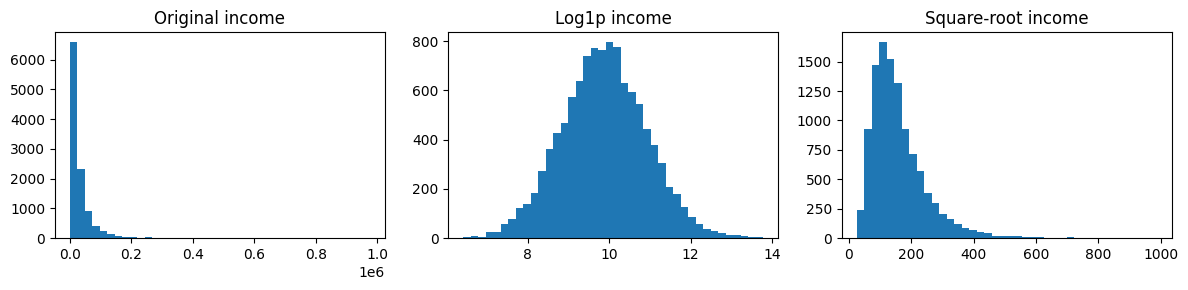

Rule: consider transformation when strong skewness harms modelling assumptions; report understandable summaries on the original income scale.


In [8]:
asym=[]
for v in main_vars:
    x=clean[v].dropna()
    asym.append([v,skew(x),kurtosis(x),x.mean(),x.median()])
display(pd.DataFrame(asym,columns=["variable","skewness","excess_kurtosis","mean","median"]).round(3))
# Log and square-root transformations for positive income
income_x=clean.income_per_season.dropna()
transforms=pd.DataFrame({
 "transformation":["Original","Log1p","Square root"],
 "skewness":[skew(income_x),skew(np.log1p(income_x)),skew(np.sqrt(income_x))]
})
display(transforms.round(3))
fig,ax=plt.subplots(1,3,figsize=(12,3))
ax[0].hist(income_x,bins=40); ax[0].set_title("Original income")
ax[1].hist(np.log1p(income_x),bins=40); ax[1].set_title("Log1p income")
ax[2].hist(np.sqrt(income_x),bins=40); ax[2].set_title("Square-root income")
plt.tight_layout(); plt.savefig(OUT/"task6_income_transformations.png",dpi=140); plt.show()
print("Rule: consider transformation when strong skewness harms modelling assumptions; report understandable summaries on the original income scale.")

## TASK 7 – Estimation and sampling

,variable,n,average_sample_mean,observed_SE_mean,sigma_over_sqrt_n,average_sample_median,SD_sample_median
0,income_per_season,30,34393.78,10064.50,9876.97,19831.66,4612.52
1,income_per_season,100,34439.80,5353.91,5409.84,19443.76,2509.55
2,income_per_season,800,34318.22,1816.92,1912.67,19305.54,876.50
3,income_per_season,3000,34318.42,831.44,987.70,19307.71,394.81


,variable,n,average_sample_mean,observed_SE_mean,sigma_over_sqrt_n,average_sample_median,SD_sample_median
0,yield_q_per_acre,30,24.045,0.611,0.618,24.138,0.790
1,yield_q_per_acre,100,24.014,0.332,0.338,24.112,0.438
2,yield_q_per_acre,800,24.039,0.116,0.120,24.124,0.147
3,yield_q_per_acre,3000,24.030,0.052,0.062,24.120,0.064


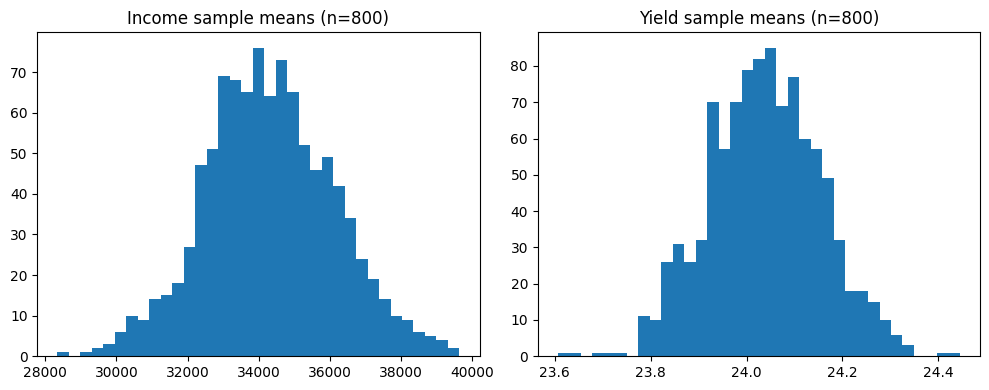

,sample_size,mean_variance_divide_n,mean_variance_divide_n_minus_1
0,5,0.789468,0.986834
1,20,0.958500,1.008948
2,100,0.982451,0.992375


Delta population mean: 34447.23 verification mean: 38598.83 verification SE: 4077.27 n: 280
Random survey mean income: 34318.7 Small-farm convenience-like subset mean: 16729.13


In [9]:
population=clean.dropna(subset=["income_per_season","yield_q_per_acre"]).copy()
def sampling_experiment(column, sizes=(30,100,800,3000), reps=1000):
    vals=population[column].to_numpy()
    rows=[]; saved={}
    for n in sizes:
        means=[]; medians=[]
        for _ in range(reps):
            s=rng.choice(vals,size=n,replace=False)
            means.append(np.mean(s)); medians.append(np.median(s))
        rows.append([column,n,np.mean(means),np.std(means,ddof=1),np.std(vals,ddof=0)/np.sqrt(n),
                     np.mean(medians),np.std(medians,ddof=1)])
        saved[n]=means
    return pd.DataFrame(rows,columns=["variable","n","average_sample_mean","observed_SE_mean","sigma_over_sqrt_n",
                                      "average_sample_median","SD_sample_median"]),saved
income_sampling,income_samples=sampling_experiment("income_per_season")
yield_sampling,yield_samples=sampling_experiment("yield_q_per_acre")
display(income_sampling.round(2)); display(yield_sampling.round(3))
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].hist(income_samples[800],bins=35); ax[0].set_title("Income sample means (n=800)")
ax[1].hist(yield_samples[800],bins=35); ax[1].set_title("Yield sample means (n=800)")
plt.tight_layout(); plt.savefig(OUT/"task7_sampling_means.png",dpi=140); plt.show()
# Variance estimator simulation
v=rng.normal(0,1,1000)
variance_demo=[]
for n in [5,20,100]:
    sims=np.array([rng.choice(v,n,replace=True) for _ in range(2000)])
    variance_demo.append([n,np.var(sims,axis=1,ddof=0).mean(),np.var(sims,axis=1,ddof=1).mean()])
display(pd.DataFrame(variance_demo,columns=["sample_size","mean_variance_divide_n","mean_variance_divide_n_minus_1"]))
# Verification sample estimate and convenience sample comparison
ver=verification.merge(clean[["farm_id","income_per_season","district"]],on="farm_id",suffixes=("_raw",""))
ver=ver.drop_duplicates("farm_id")
district_choice="Delta"
pop_d=population[population.district==district_choice].income_per_season
ver_d=ver[ver.district==district_choice].income_per_season.dropna()
print(district_choice,"population mean:",round(pop_d.mean(),2),"verification mean:",round(ver_d.mean(),2),
      "verification SE:",round(ver_d.std()/np.sqrt(len(ver_d)),2),"n:",len(ver_d))
convenience=population[population.farm_size_acres<population.farm_size_acres.quantile(.5)].sample(
    min(800,(population.farm_size_acres<population.farm_size_acres.quantile(.5)).sum()),random_state=SEED)
print("Random survey mean income:",round(population.income_per_season.mean(),2),
      "Small-farm convenience-like subset mean:",round(convenience.income_per_season.mean(),2))

## TASK 8 – Covariance and correlation

,rainfall_mm,fertiliser_kg_per_acre,farm_size_acres,yield_q_per_acre,income_per_season,loan_amount
rainfall_mm,76711.66,-73.75,-1.59,584.35,-3.081705e+04,9.336379e+04
fertiliser_kg_per_acre,-73.75,485.53,-2.06,11.30,-1.481864e+04,4.952600e+03
farm_size_acres,-1.59,-2.06,125.75,0.24,2.831074e+05,1.231091e+05
yield_q_per_acre,584.35,11.30,0.24,11.52,9.527530e+03,1.415940e+03
income_per_season,-30817.05,-14818.64,283107.40,9527.53,2.902361e+09,2.496031e+08
loan_amount,93363.79,4952.60,123109.07,1415.94,2.496031e+08,1.008227e+09


,rainfall_mm,fertiliser_kg_per_acre,farm_size_acres,yield_q_per_acre,income_per_season,loan_amount
rainfall_mm,1.000,-0.012,-0.001,0.622,-0.002,0.011
fertiliser_kg_per_acre,-0.012,1.000,-0.008,0.151,-0.012,0.007
farm_size_acres,-0.001,-0.008,1.000,0.006,0.469,0.346
yield_q_per_acre,0.622,0.151,0.006,1.000,0.052,0.013
income_per_season,-0.002,-0.012,0.469,0.052,1.000,0.146
loan_amount,0.011,0.007,0.346,0.013,0.146,1.000


,rainfall_mm,fertiliser_kg_per_acre,farm_size_acres,yield_q_per_acre,income_per_season,loan_amount
rainfall_mm,1.000,-0.012,0.004,0.619,-0.010,0.017
fertiliser_kg_per_acre,-0.012,1.000,0.001,0.140,0.004,0.003
farm_size_acres,0.004,0.001,1.000,0.019,0.620,0.330
yield_q_per_acre,0.619,0.140,0.019,1.000,0.077,0.019
income_per_season,-0.010,0.004,0.620,0.077,1.000,0.209
loan_amount,0.017,0.003,0.330,0.019,0.209,1.000


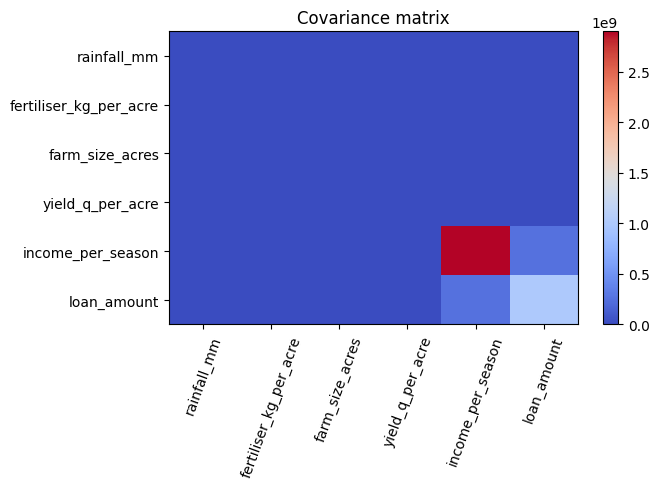

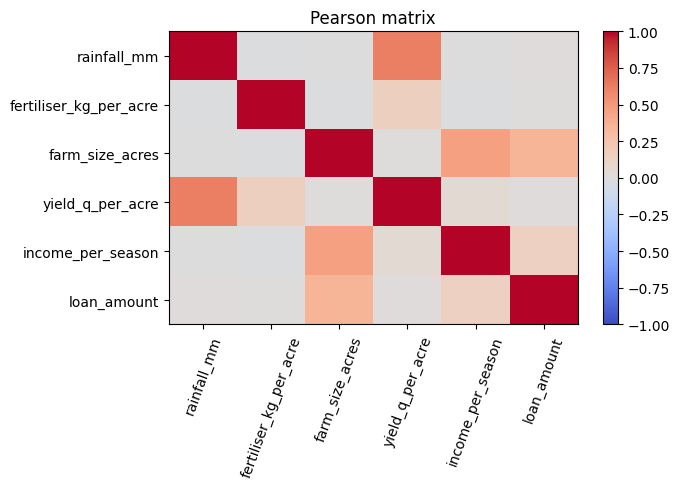

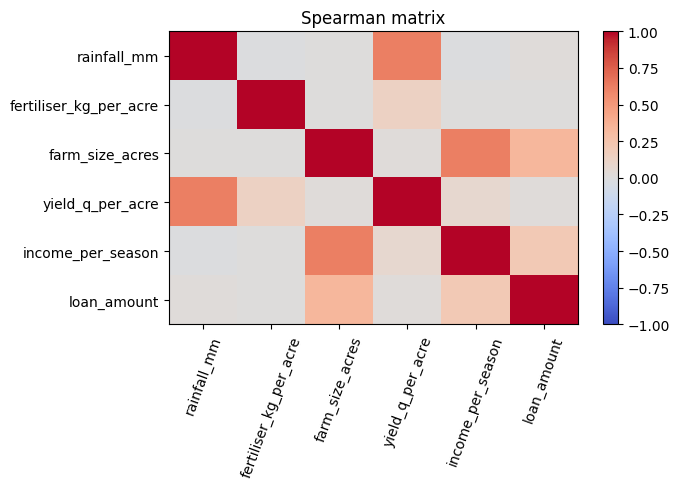

Rainfall/yield Pearson: 0.6217408639318943
Rainfall/yield Spearman: 0.6190051346563752


,pearson_rain_yield,spearman_rain_yield
district,,
Delta,0.156953,0.154090
Dry,0.318980,0.304108
Hill,0.225091,0.206289


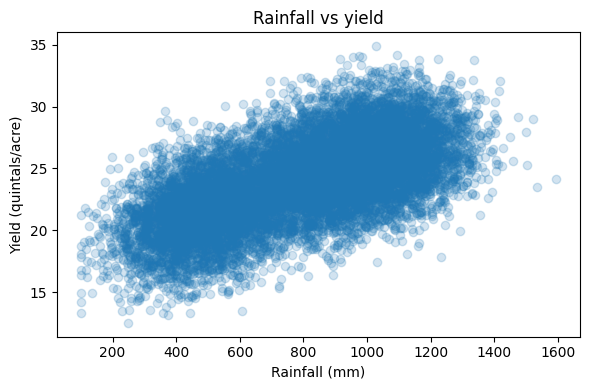

Correlation describes association, not causation; irrigation, crop and soil may confound the relationship.


In [10]:
corr_vars=["rainfall_mm","fertiliser_kg_per_acre","farm_size_acres","yield_q_per_acre","income_per_season","loan_amount"]
corr_data=clean[corr_vars].dropna()
cov=corr_data.cov()
pearson=corr_data.corr(method="pearson")
spearman=corr_data.corr(method="spearman")
display(cov.round(2)); display(pearson.round(3)); display(spearman.round(3))
for name,matrix in [("Covariance",cov),("Pearson",pearson),("Spearman",spearman)]:
    plt.figure(figsize=(7,5)); plt.imshow(matrix,cmap="coolwarm",vmin=-1 if name!="Covariance" else None,
        vmax=1 if name!="Covariance" else None,aspect="auto")
    plt.xticks(range(len(corr_vars)),corr_vars,rotation=70); plt.yticks(range(len(corr_vars)),corr_vars)
    plt.colorbar(); plt.title(name+" matrix"); plt.tight_layout(); plt.savefig(OUT/f"task8_{name.lower()}_heatmap.png",dpi=140); plt.show()
# Rainfall-yield comparison and district-wise coefficients
print("Rainfall/yield Pearson:",corr_data.rainfall_mm.corr(corr_data.yield_q_per_acre,method="pearson"))
print("Rainfall/yield Spearman:",corr_data.rainfall_mm.corr(corr_data.yield_q_per_acre,method="spearman"))
display(clean.groupby("district").apply(lambda g: pd.Series({
 "pearson_rain_yield":g.rainfall_mm.corr(g.yield_q_per_acre,method="pearson"),
 "spearman_rain_yield":g.rainfall_mm.corr(g.yield_q_per_acre,method="spearman")
}),include_groups=False))
plt.figure(figsize=(6,4)); plt.scatter(clean.rainfall_mm,clean.yield_q_per_acre,alpha=.2); plt.xlabel("Rainfall (mm)"); plt.ylabel("Yield (quintals/acre)"); plt.title("Rainfall vs yield"); plt.tight_layout(); plt.savefig(OUT/"task8_rainfall_yield.png",dpi=140); plt.show()
print("Correlation describes association, not causation; irrigation, crop and soil may confound the relationship.")

## TASK 9 – Predict, then test

In [11]:
predictions=pd.DataFrame([
 ["Income skewness","Positive; mean greater than median","Income generated from a log-normal-like distribution"],
 ["Remove top 1% income","Mean should fall substantially; income-yield correlation may change","Extreme incomes influence the mean and Pearson correlation"],
 ["Multiply sample size by four","Standard error should roughly halve","SE is proportional to 1/sqrt(n)"],
 ["Rainfall-yield correlation","Spearman may capture the curved monotonic portion differently from Pearson","Relationship is deliberately nonlinear"]
],columns=["Question","Prediction","Reason"])
display(predictions)
inc=population.income_per_season
trimmed=inc[inc<=inc.quantile(.99)]
print("Income skewness:",round(skew(inc),3),"mean:",round(inc.mean(),2),"median:",round(inc.median(),2))
print("Mean after removing top 1%:",round(trimmed.mean(),2))
print("Income-yield Pearson full:",round(population.income_per_season.corr(population.yield_q_per_acre),3))
p99=population[population.income_per_season<=population.income_per_season.quantile(.99)]
print("Income-yield Pearson after top 1% removal:",round(p99.income_per_season.corr(p99.yield_q_per_acre),3))
print("Compare observed SE values at n and 4n in Task 7; theoretical ratio is 0.5.")

,Question,Prediction,Reason
0,Income skewness,Positive; mean greater than median,Income generated from a log-normal-like distri...
1,Remove top 1% income,Mean should fall substantially; income-yield c...,Extreme incomes influence the mean and Pearson...
2,Multiply sample size by four,Standard error should roughly halve,SE is proportional to 1/sqrt(n)
3,Rainfall-yield correlation,Spearman may capture the curved monotonic port...,Relationship is deliberately nonlinear


Income skewness: 6.885 mean: 34318.7 median: 19318.9
Mean after removing top 1%: 30441.55
Income-yield Pearson full: 0.051
Income-yield Pearson after top 1% removal: 0.061
Compare observed SE values at n and 4n in Task 7; theoretical ratio is 0.5.


## TASK 10 – Interpret, integrate and recommend

In [12]:
team_results=clean.groupby("district").agg(
    farms=("farm_id","nunique"),median_yield=("yield_q_per_acre","median"),
    mean_yield=("yield_q_per_acre","mean"),median_income=("income_per_season","median"),
    income_IQR=("income_per_season",lambda s:s.quantile(.75)-s.quantile(.25))).reset_index()
display(team_results.round(2))
print("Extension planning: report district/crop median yield and median income with IQR.")
print("Credit/insurance: report income and loan quantiles; manually verify extreme farms and unit anomalies.")
print("Research: report Pearson and Spearman correlations plus confidence/standard-error information.")
print("Limitations: synthetic data, assumed distributions, possible unmeasured confounding and sample uncertainty.")

,district,farms,median_yield,mean_yield,median_income,income_IQR
0,Delta,4806,26.09,26.13,19190.63,28761.17
1,Dry,4126,21.39,21.34,19253.06,29543.24
2,Hill,3068,24.35,24.35,19525.09,28678.65


Extension planning: report district/crop median yield and median income with IQR.
Credit/insurance: report income and loan quantiles; manually verify extreme farms and unit anomalies.
Research: report Pearson and Spearman correlations plus confidence/standard-error information.
Limitations: synthetic data, assumed distributions, possible unmeasured confounding and sample uncertainty.


## TASK 11 – Day-4 design challenge: 1.2 million farms, 20 districts, mixed populations and volunteers

In [13]:
# Simulate a larger challenge sample (200,000 rows as a scalable benchmark proxy)
M=200_000
mix_group=rng.choice(["Smallholder","Commercial"],M,p=[.96,.04])
mix_income=np.where(mix_group=="Smallholder",rng.lognormal(10.1,.7,M),rng.lognormal(13.0,.9,M))
volunteer=rng.random(M)<.40
# Volunteers are deliberately biased toward larger farms/income
mix_income[volunteer]*=1.35
challenge=pd.DataFrame({"group":mix_group,"income":mix_income,"volunteer":volunteer})
challenge_summary=challenge.groupby(["group","volunteer"]).income.agg(["count","mean","median","std","skew"]).reset_index()
display(challenge_summary.round(2))
random_sample=challenge.sample(5000,random_state=SEED)
vol_sample=challenge[challenge.volunteer].sample(5000,random_state=SEED)
print("Random-sample mean:",round(random_sample.income.mean(),2))
print("Volunteer-sample mean:",round(vol_sample.income.mean(),2))
print("Full simulated population mean:",round(challenge.income.mean(),2))
# Benchmark grouped summaries at increasing sizes
bench=[]
for n in [10000,50000,100000,200000]:
    part=challenge.iloc[:n]
    t0=time.perf_counter()
    result=part.groupby("group").income.agg(["mean","median","std","skew"])
    elapsed=time.perf_counter()-t0
    bench.append([n,round(elapsed,4),round(part.memory_usage(deep=True).sum()/1024**2,2)])
display(pd.DataFrame(bench,columns=["rows","groupby_seconds","memory_MB"]))
print("Decision: MODIFY the design.")
print("- Stratify summaries by district and farm type; do not combine smallholders and estates without context.")
print("- Keep volunteer records separate from probability-sample estimates, or use defensible non-response/propensity weights.")
print("- Report median, IQR and upper-tail quantiles alongside mean and standard deviation.")
print("- Review extreme incomes as a separate tail; do not automatically remove genuine commercial farms.")
print("- Use chunked processing/Parquet and monthly validation for 1.2 million farms and additional variables.")
print("- Recalculate standard errors using the sampling design and weights; volunteer samples are not automatically representative.")

,group,volunteer,count,mean,median,std,skew
0,Commercial,False,4809,657553.94,446384.63,738431.54,4.53
1,Commercial,True,3175,897775.70,609017.99,982425.44,3.85
2,Smallholder,False,115280,31117.49,24338.54,24643.79,2.91
3,Smallholder,True,76736,41910.84,32667.39,33412.83,2.85


Random-sample mean: 67249.96
Volunteer-sample mean: 71136.61
Full simulated population mean: 64079.55


,rows,groupby_seconds,memory_MB
0,10000,0.0040,0.66
1,50000,0.0129,3.29
2,100000,0.0209,6.58
3,200000,0.0434,13.15


Decision: MODIFY the design.
- Stratify summaries by district and farm type; do not combine smallholders and estates without context.
- Keep volunteer records separate from probability-sample estimates, or use defensible non-response/propensity weights.
- Report median, IQR and upper-tail quantiles alongside mean and standard deviation.
- Review extreme incomes as a separate tail; do not automatically remove genuine commercial farms.
- Use chunked processing/Parquet and monthly validation for 1.2 million farms and additional variables.
- Recalculate standard errors using the sampling design and weights; volunteer samples are not automatically representative.


## Final checklist and generated files

After running all cells:
- `farm_survey_raw.csv` and `verification_sample_raw.csv` are saved in `DSA04_CO3_outputs`.
- All figures are saved in the same output folder.
- Tables are displayed directly below their code cells.
- Use the actual outputs from your run in the report; do not copy assumed values.

**Submission reminder:** The assignment requires source code/notebook, dataset or generator, figures/tables and a PDF report. This notebook supplies the implementation and evidence-generation workflow; write your conclusions from your actual Colab results.